# Módulo 3: Extracción de Características, Análisis de Textura y Dinámica Temporal

**Objetivo.** Extraer métricas morfológicas y de textura de la ROI segmentada y procesar la totalidad del video para cuantificar parámetros fisiológicos del reflejo fotomotor.

**Datos.** Se utiliza el mismo frame y la misma ROI que en los módulos anteriores. La segmentación de la pupila corresponde al procedimiento elegido en el Módulo 2 (watershed con marcadores robustos, cierre y envolvente convexa), implementado en `src/segmentacion.py`.

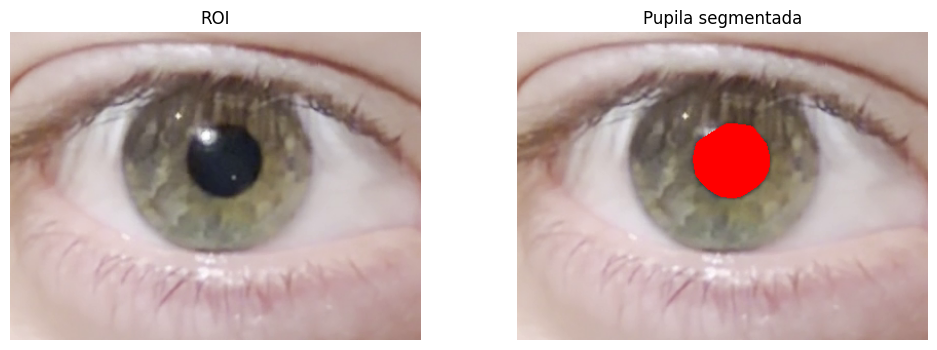

In [2]:
import sys
sys.path.append("..")     # para encontrar config.py y la carpeta src

import cv2
import numpy as np
import matplotlib.pyplot as plt
from config import VIDEO_PATH
from src.segmentacion import segmentar_pupila


# Mismo frame y ROI que en los módulos anteriores
FRAME_IDX = 778
x, y, w, h = 300, 950, 400, 300

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read()
cap.release()

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
roi = frame_rgb[y:y+h, x:x+w]
roi_gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)

# Máscara de la pupila con el método del Módulo 2
mascara = segmentar_pupila(roi)

superpuesta = roi.copy()
superpuesta[mascara == 255] = [255, 0, 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(roi)
axes[0].set_title("ROI")
axes[1].imshow(superpuesta)
axes[1].set_title("Pupila segmentada")
for ax in axes:
    ax.axis("off")
plt.show()

## 1. Descriptores Morfométricos y de Textura en el Frame Segmentado

### Descriptores morfométricos

A partir de la máscara binaria de la pupila se calculan:
- Área (A): cantidad de píxeles de la región.
- Perímetro (P): longitud del contorno de la región.
- Centroide $(X_c, Y_c)$: promedio de las coordenadas de los píxeles de la región.
- Circularidad: $C = \dfrac{4\pi A}{P^2}$. Vale 1 para un círculo perfecto y disminuye cuanto más irregular o alargada es la forma.
- Excentricidad: se ajusta a la región una elipse con los mismos momentos de segundo orden y se calcula la relación entre la distancia focal y su eje mayor. Vale 0 para un círculo y tiende a 1 para una forma alargada.
- Diámetro equivalente: diámetro de un círculo con la misma área que la región, $D = \sqrt{4A/\pi}$.

Área:                  4224 px
Perímetro:             241.0 px
Centroide (Xc, Yc):    (208.4, 124.7) px
Circularidad:          0.914
Excentricidad:         0.321
Diámetro equivalente:  73.3 px
Ejes de la elipse:     75.4 × 71.4 px


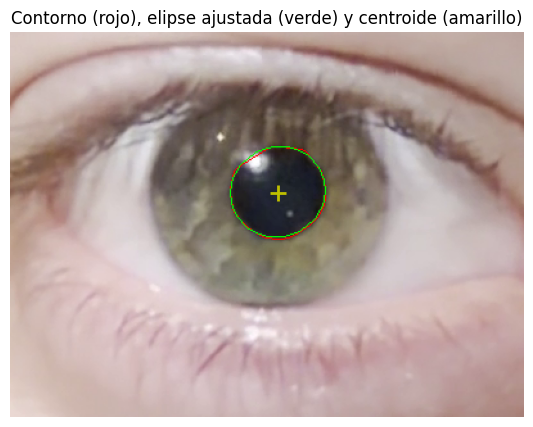

In [3]:
from skimage.measure import regionprops, label

# ---------------------------------------------------------------
# Propiedades de la región blanca de la máscara
# ---------------------------------------------------------------
# label numera las regiones conectadas; regionprops calcula
# las medidas de cada una. Como hay una sola (la pupila), tomamos [0]
props = regionprops(label(mascara > 0))[0]

area = props.area
perimetro = props.perimeter
yc, xc = props.centroid                     # skimage devuelve (fila, columna)
circularidad = 4 * np.pi * area / perimetro ** 2
excentricidad = props.eccentricity
diametro_eq = props.equivalent_diameter_area

print(f"Área:                  {area:.0f} px")
print(f"Perímetro:             {perimetro:.1f} px")
print(f"Centroide (Xc, Yc):    ({xc:.1f}, {yc:.1f}) px")
print(f"Circularidad:          {circularidad:.3f}")
print(f"Excentricidad:         {excentricidad:.3f}")
print(f"Diámetro equivalente:  {diametro_eq:.1f} px")
print(f"Ejes de la elipse:     {props.axis_major_length:.1f} × {props.axis_minor_length:.1f} px")

# ---------------------------------------------------------------
# Visualización: contorno, centroide y elipse ajustada
# ---------------------------------------------------------------
vis = roi.copy()
contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(vis, contornos, -1, (255, 0, 0), 1)

# Elipse con los mismos momentos que la región
# (OpenCV pide el ángulo en grados y los semiejes)
angulo = -np.degrees(props.orientation) + 90
cv2.ellipse(vis, (int(xc), int(yc)),
            (int(props.axis_major_length / 2), int(props.axis_minor_length / 2)),
            angulo, 0, 360, (0, 255, 0), 1)

plt.figure(figsize=(7, 5))
plt.imshow(vis)
plt.plot(xc, yc, "y+", markersize=12, mew=2)
plt.title("Contorno (rojo), elipse ajustada (verde) y centroide (amarillo)")
plt.axis("off")
plt.show()

La pupila segmentada en el frame 778 tiene un área de 4224 px y un perímetro de 241 px, con su centroide ubicado en (208,4; 124,7) px dentro de la ROI. Su diámetro equivalente, es decir, el de un círculo con la misma área, es de 73,3 px.

La circularidad obtenida es de 0,914, cercana a 1, lo que indica una forma muy próxima a un círculo. Parte de la diferencia respecto del valor ideal se debe a que el contorno está formado por píxeles discretos: el perímetro de una figura "escalonada" resulta algo mayor que el de un círculo continuo, lo que reduce la circularidad aunque la forma sea redonda. También contribuye el tramo recto que introduce la envolvente convexa en la zona del reflejo corneal.

La excentricidad es de 0,321, y la elipse ajustada tiene ejes de 75,4 y 71,4 px, por lo que el eje menor es aproximadamente un 95 % del mayor. Aunque el valor de excentricidad pueda parecer alto, esta medida es muy sensible cerca de la forma circular: una diferencia de solo el 5 % entre los ejes ya produce una excentricidad de alrededor de 0,3. La leve elongación puede deberse a que la cámara no estaba perfectamente frontal al ojo, lo que hace que la pupila se proyecte como una elipse, o a pequeñas irregularidades de la segmentación.

En conclusión, ambos descriptores indican que la pupila presenta una forma regular, sin deformaciones significativas.

### Textura de primer orden

La textura de primer orden describe la distribución de intensidades de una región a partir de su histograma, sin considerar la posición de los píxeles. Se calculan cuatro estadísticos:
- **Media:** intensidad promedio de la región.
- **Desvío estándar:** dispersión de las intensidades alrededor de la media; cuanto mayor, más contraste interno.
- **Entropía:** $H = -\sum_i p_i \log_2 p_i$, donde $p_i$ es la probabilidad de cada nivel de gris. Mide la aleatoriedad o complejidad de la distribución: es baja si predominan pocos niveles y alta si las intensidades están repartidas en muchos niveles.
- **Asimetría (skewness):** indica si el histograma tiene una cola hacia valores altos (positiva) o bajos (negativa).

Se calculan por separado en los canales R, G y B, sobre dos regiones: la **pupila**, obtenida con la segmentación del Módulo 2, y el **iris**, definido como el anillo entre el borde de la pupila y el borde externo del iris. El borde del iris se detecta con la transformada de Hough para círculos. Para la entropía, cada canal se cuantiza a 64 niveles de gris.

Iris: centro (202, 124) px, radio 94 px


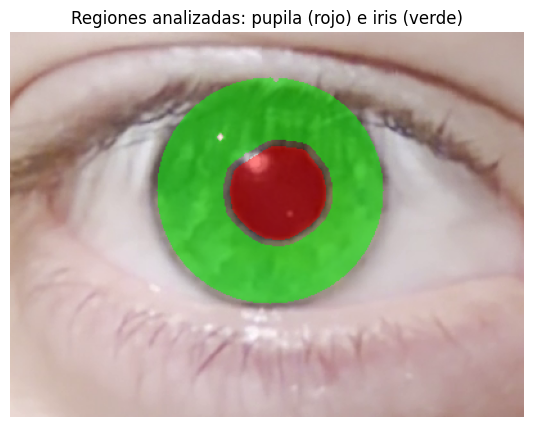

In [4]:
# 1) Borde externo del iris con la transformada de Hough
# Radio aproximado de la pupila (a partir de su área)
radio_pupila = np.sqrt(area / np.pi)

# Suavizamos con mediana para que la textura del iris no genere
# círculos falsos
gris_suave = cv2.medianBlur(roi_gris, 7)

# HoughCircles busca círculos en la imagen:
#   minDist=1000      → como es muy grande, devuelve un solo círculo
#   param1            → umbral para detectar bordes
#   param2            → cuántos "votos" necesita un círculo (más bajo = más permisivo)
#   min/maxRadius     → el iris mide entre 2 y 4 veces el radio de la pupila
circulos = cv2.HoughCircles(
    gris_suave, cv2.HOUGH_GRADIENT, dp=1, minDist=1000,
    param1=60, param2=20,
    minRadius=int(2 * radio_pupila), maxRadius=int(4 * radio_pupila)
)
x_iris, y_iris, radio_iris = circulos[0][0]
print(f"Iris: centro ({x_iris:.0f}, {y_iris:.0f}) px, radio {radio_iris:.0f} px")


# 2) Máscara del iris: anillo entre la pupila y el borde del iris
# Círculo del iris un 5 % más chico, para no incluir la esclerótica
disco_iris = np.zeros_like(roi_gris)
cv2.circle(disco_iris, (int(x_iris), int(y_iris)), int(0.95 * radio_iris), 255, -1)

# Pupila agrandada unos píxeles, para no incluir su borde
ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
pupila_agrandada = cv2.dilate(mascara, ee)

# Iris = disco del iris, sin la pupila y sin reflejos (píxeles muy claros)
mascara_iris = (disco_iris > 0) & (pupila_agrandada == 0) & (roi_gris < 170)
mascara_pupila = mascara > 0


# 3) Visualización
vis = roi.copy()
vis[mascara_iris] = (0.5 * vis[mascara_iris] + [0, 127, 0]).astype(np.uint8)
vis[mascara_pupila] = (0.5 * vis[mascara_pupila] + [127, 0, 0]).astype(np.uint8)

plt.figure(figsize=(7, 5))
plt.imshow(vis)
plt.title("Regiones analizadas: pupila (rojo) e iris (verde)")
plt.axis("off")
plt.show()

Media  Desvío  Entropía (bits)  Asimetría
Región Canal                                            
Pupila R       46.12   36.05             3.66       3.75
       G       46.30   35.51             3.55       3.94
       B       52.30   35.20             3.78       3.85
Iris   R      120.35   24.10             4.53       0.05
       G      109.62   27.19             4.67      -0.04
       B       95.65   24.52             4.58       0.13

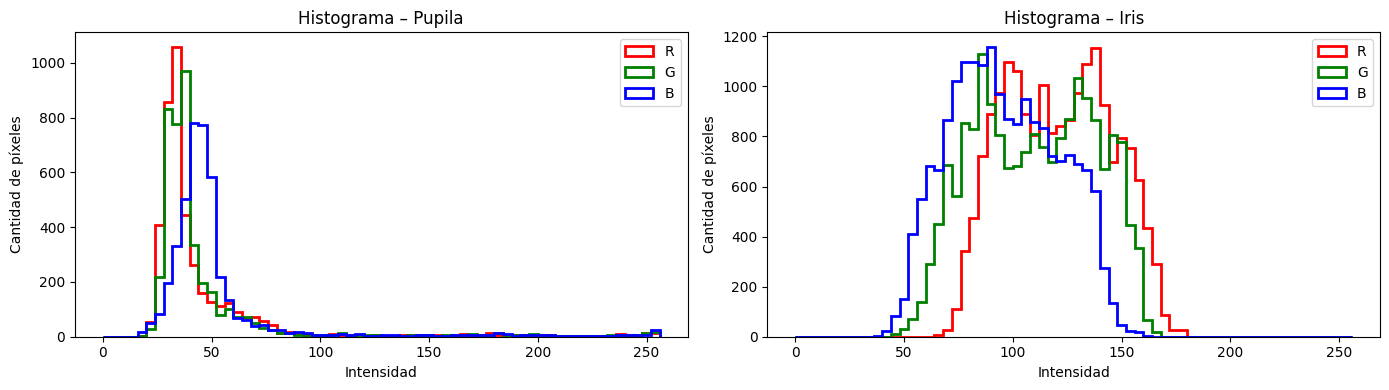

In [5]:
import pandas as pd
from scipy.stats import skew


# Entropía de un conjunto de valores, cuantizados a 64 niveles
def entropia(valores, niveles=64):
    cuantizados = valores // (256 // niveles)                 # 0..63
    conteo = np.bincount(cuantizados, minlength=niveles)
    p = conteo / conteo.sum()                                 # probabilidades
    p = p[p > 0]                                              # log(0) no está definido
    return -np.sum(p * np.log2(p))

# Estadísticos por región y por canal
regiones = {"Pupila": mascara_pupila, "Iris": mascara_iris}
canales = {"R": 0, "G": 1, "B": 2}

filas = []
for nombre_region, region in regiones.items():
    for nombre_canal, c in canales.items():
        # Valores del canal solo dentro de la región (lista 1D de píxeles)
        valores = roi[:, :, c][region]
        filas.append({
            "Región": nombre_region,
            "Canal": nombre_canal,
            "Media": valores.mean(),
            "Desvío": valores.std(),
            "Entropía (bits)": entropia(valores),
            "Asimetría": skew(valores.astype(float)),
        })

df_primer_orden = pd.DataFrame(filas).set_index(["Región", "Canal"]).round(2)
display(df_primer_orden)


# Histogramas del iris en cada canal
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nombre_region, region) in zip(axes, regiones.items()):
    for nombre_canal, c in canales.items():
        ax.hist(roi[:, :, c][region], bins=64, range=(0, 256),
                histtype="step", linewidth=2,
                color={"R": "red", "G": "green", "B": "blue"}[nombre_canal],
                label=nombre_canal)
    ax.set_title(f"Histograma – {nombre_region}")
    ax.set_xlabel("Intensidad")
    ax.set_ylabel("Cantidad de píxeles")
    ax.legend()
plt.tight_layout()
plt.show()